In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv("../data/clean_footfall_sales.csv", parse_dates=["date"])
print(df.shape)
df.head()

(293847, 57)


,store,date,grocery,dairy,frozen,bottle,mvpclub,groccoup,meat,meatfroz,...,Total_Sales,Total_Coupons,Net_Sales,year,month,day_of_week,dow_num,is_weekend,week_of_year,Sales_Per_Customer
0,2,1989-01-01,15344.00,3664.00,3893.00,0.00,0.0,0.00,2568.00,0.00,...,33812.00,0.00,33812.00,1989,1,Sunday,6,1,52,12.682671
1,2,1989-01-02,18697.94,4469.68,3265.30,0.79,0.0,-7.31,3295.24,381.03,...,43389.60,156.53,43233.07,1989,1,Monday,0,0,1,22.160163
2,2,1989-01-03,15937.48,3784.45,2497.81,5.30,0.0,-13.53,4174.91,407.65,...,38402.52,175.27,38227.25,1989,1,Tuesday,1,0,1,21.538149
3,2,1989-01-04,15406.14,3434.84,2541.58,5.98,0.0,-6.95,3641.49,377.74,...,36861.66,358.91,36502.75,1989,1,Wednesday,2,0,1,20.547191
4,2,1989-01-05,16843.75,4052.65,3101.68,0.72,0.0,-69.31,4608.63,411.80,...,41232.57,220.32,41012.25,1989,1,Thursday,3,0,1,21.112427


In [2]:
print(f"Rows: {len(df):,}  |  Stores: {df['store'].nunique()}  |  "
      f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
df[["custcoun", "Total_Sales", "Sales_Per_Customer"]].describe()

Rows: 293,847  |  Stores: 122  |  Date range: 1989-01-01 to 1997-04-30


,custcoun,Total_Sales,Sales_Per_Customer
count,293847.000000,293847.000000,293847.000000
mean,2832.931392,66020.137349,22.723268
std,952.978453,34417.800372,7.655757
min,106.000000,586.020000,1.134702
25%,2121.000000,42165.180000,18.077614
50%,2714.000000,57333.290000,21.623240
75%,3389.000000,80500.355000,26.061344
max,17898.000000,299378.660000,1459.684867


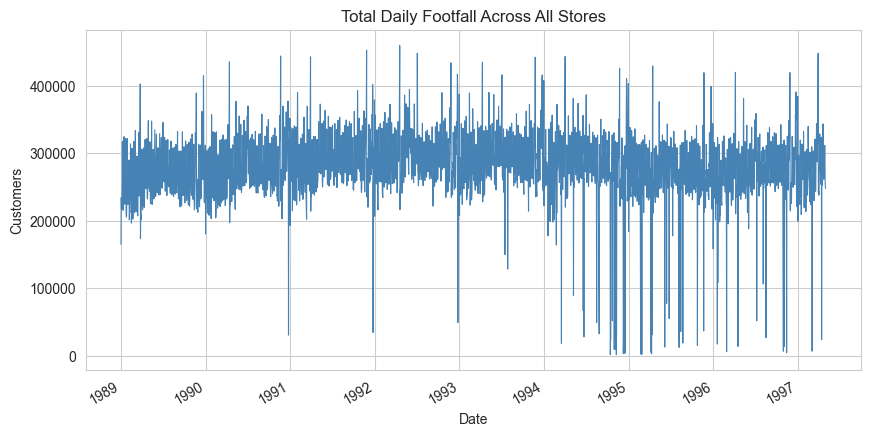

In [3]:
daily = df.groupby("date")["custcoun"].sum()

fig, ax = plt.subplots()
daily.plot(ax=ax, color="steelblue", linewidth=0.8)
ax.set_title("Total Daily Footfall Across All Stores")
ax.set_ylabel("Customers")
ax.set_xlabel("Date")
save(fig, "01_footfall_over_time")
plt.show()

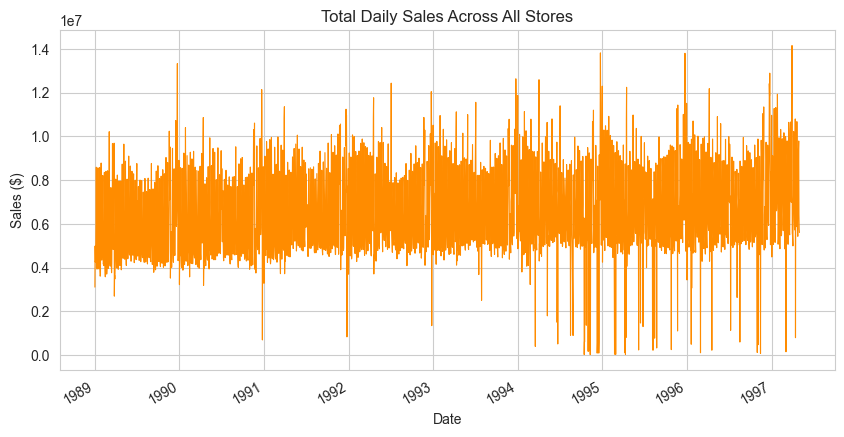

In [4]:
daily_sales = df.groupby("date")["Total_Sales"].sum()

fig, ax = plt.subplots()
daily_sales.plot(ax=ax, color="darkorange", linewidth=0.8)
ax.set_title("Total Daily Sales Across All Stores")
ax.set_ylabel("Sales ($)")
ax.set_xlabel("Date")
save(fig, "02_sales_over_time")
plt.show()

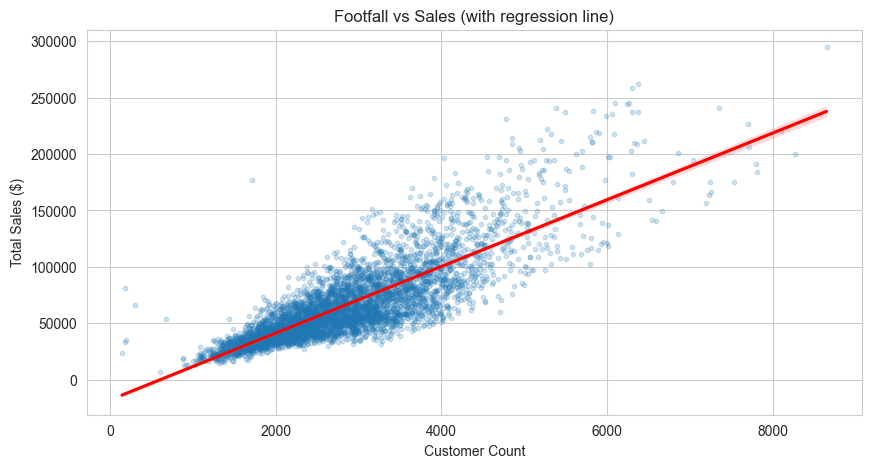

In [5]:
sample = df.sample(5000, random_state=42)  # full 294k points would be unreadable

fig, ax = plt.subplots()
sns.regplot(data=sample, x="custcoun", y="Total_Sales", ax=ax,
            scatter_kws={"alpha": 0.2, "s": 10}, line_kws={"color": "red"})
ax.set_title("Footfall vs Sales (with regression line)")
ax.set_xlabel("Customer Count")
ax.set_ylabel("Total Sales ($)")
save(fig, "03_04_footfall_vs_sales_regression")
plt.show()

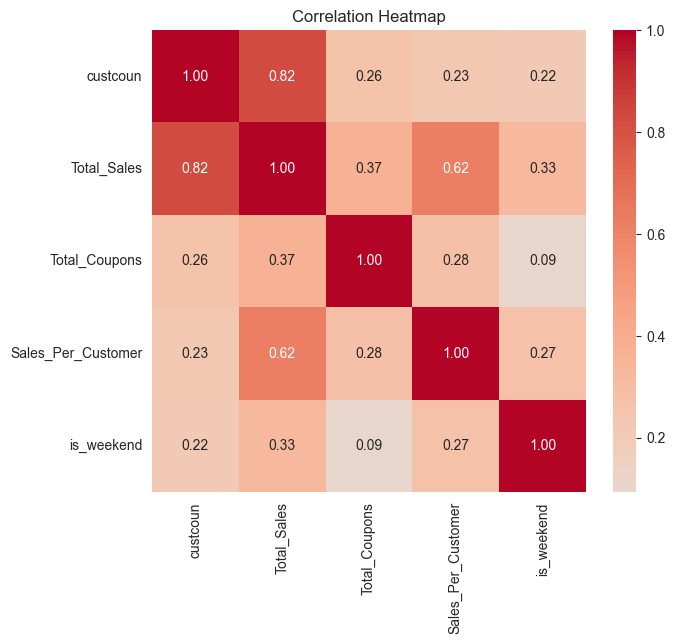

In [6]:
corr_cols = ["custcoun", "Total_Sales", "Total_Coupons", "Sales_Per_Customer", "is_weekend"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax)
ax.set_title("Correlation Heatmap")
save(fig, "05_correlation_heatmap")
plt.show()

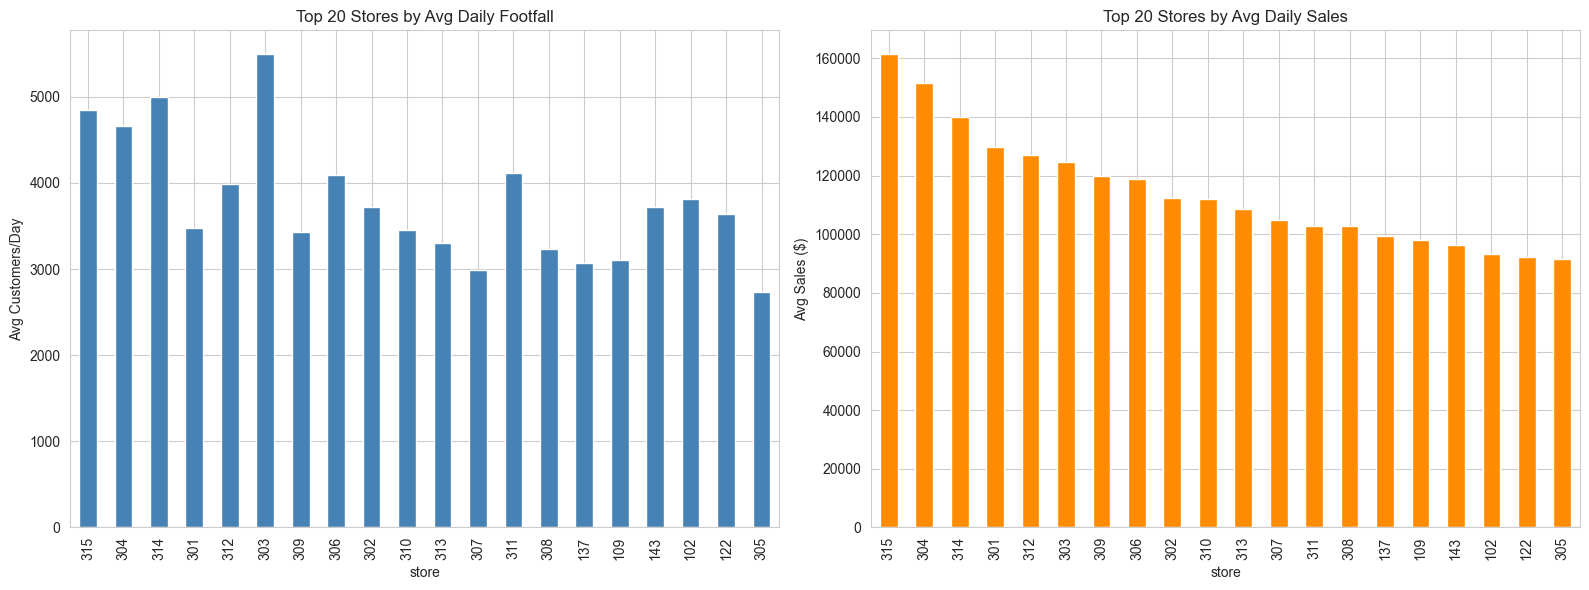

In [7]:
store_stats = df.groupby("store").agg(
    avg_footfall=("custcoun", "mean"),
    avg_sales=("Total_Sales", "mean")
).sort_values("avg_sales", ascending=False)

top20 = store_stats.head(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top20["avg_footfall"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Top 20 Stores by Avg Daily Footfall")
axes[0].set_ylabel("Avg Customers/Day")

top20["avg_sales"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Top 20 Stores by Avg Daily Sales")
axes[1].set_ylabel("Avg Sales ($)")

plt.tight_layout()
save(fig, "06_07_store_comparison")
plt.show()

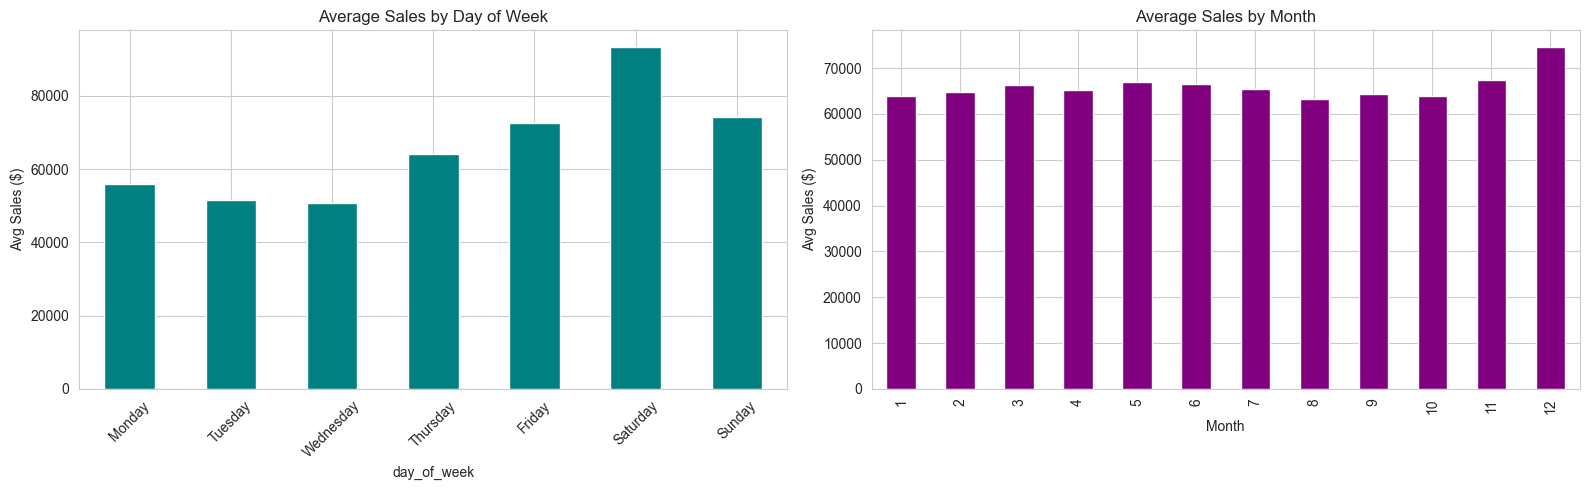

In [8]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_sales = df.groupby("day_of_week")["Total_Sales"].mean().reindex(dow_order)
month_sales = df.groupby("month")["Total_Sales"].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
dow_sales.plot(kind="bar", ax=axes[0], color="teal")
axes[0].set_title("Average Sales by Day of Week")
axes[0].set_ylabel("Avg Sales ($)")
axes[0].tick_params(axis="x", rotation=45)

month_sales.plot(kind="bar", ax=axes[1], color="purple")
axes[1].set_title("Average Sales by Month")
axes[1].set_ylabel("Avg Sales ($)")
axes[1].set_xlabel("Month")

plt.tight_layout()
save(fig, "08_sales_by_time_period")
plt.show()

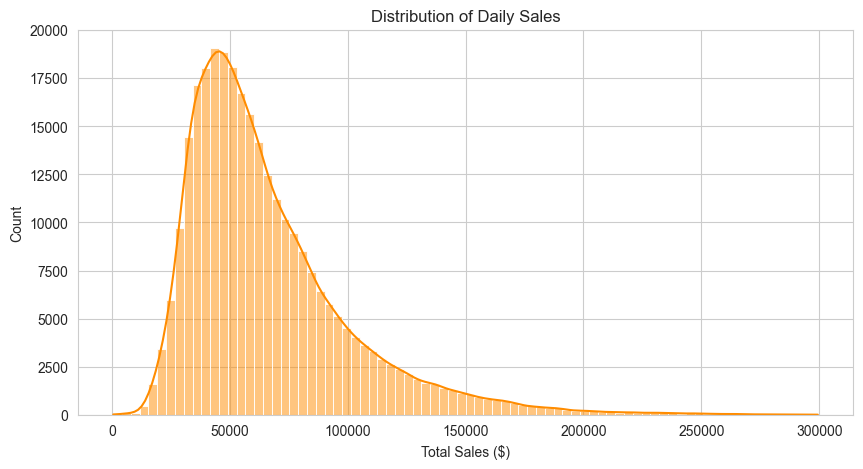

In [9]:
fig, ax = plt.subplots()
sns.histplot(df["Total_Sales"], bins=80, kde=True, ax=ax, color="darkorange")
ax.set_title("Distribution of Daily Sales")
ax.set_xlabel("Total Sales ($)")
save(fig, "09_sales_distribution")
plt.show()

In [10]:
## EDA Summary

- Footfall and sales track each other closely over time (correlation ≈ 0.82).
- Saturday is consistently the highest-traffic and highest-sales day; midweek (Tue/Wed) is lowest.
- Store performance varies substantially — the top 20 stores by sales are not always the top 20 by footfall, meaning basket size/spend-per-customer also matters, not just traffic volume.
- Sales are right-skewed: most days cluster around the median (~$57k) with a long tail of high-volume stores/days.

SyntaxError: invalid character '≈' (U+2248) (1062354917.py, line 3)

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Libraries loaded")

Libraries loaded


In [12]:
X1 = df[["custcoun"]]
y = df["Total_Sales"]

X1_train, X1_test, y_train, y_test = train_test_split(
    X1, y, test_size=0.2, random_state=42
)

model1 = LinearRegression()
model1.fit(X1_train, y_train)
pred1 = model1.predict(X1_test)

r2_1 = r2_score(y_test, pred1)
mae_1 = mean_absolute_error(y_test, pred1)
rmse_1 = mean_squared_error(y_test, pred1) ** 0.5

print("MODEL 1 - Simple Linear Regression")
print(f"  Sales = {model1.intercept_:.2f} + {model1.coef_[0]:.2f} * Footfall")
print(f"  R²   = {r2_1:.4f}")
print(f"  MAE  = ${mae_1:,.2f}")
print(f"  RMSE = ${rmse_1:,.2f}")

MODEL 1 - Simple Linear Regression
  Sales = -17910.41 + 29.62 * Footfall
  R²   = 0.6703
  MAE  = $14,023.98
  RMSE = $19,645.46


In [13]:
dow_dummies = pd.get_dummies(df["day_of_week"], drop_first=True)  # avoid dummy trap
features = pd.concat([df[["custcoun", "is_weekend", "month"]], dow_dummies], axis=1)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    features, y, test_size=0.2, random_state=42
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
pred2 = model2.predict(X2_test)

r2_2 = r2_score(y2_test, pred2)
mae_2 = mean_absolute_error(y2_test, pred2)
rmse_2 = mean_squared_error(y2_test, pred2) ** 0.5

print("MODEL 2 - Multiple Linear Regression")
print(f"  R²   = {r2_2:.4f}")
print(f"  MAE  = ${mae_2:,.2f}")
print(f"  RMSE = ${rmse_2:,.2f}\n")

coef_table = pd.Series(model2.coef_, index=features.columns).sort_values(ascending=False)
print("Coefficients:")
print(coef_table.round(2))

MODEL 2 - Multiple Linear Regression
  R²   = 0.7092
  MAE  = $13,048.21
  RMSE = $18,451.26

Coefficients:
Saturday       4976.12
is_weekend     2916.11
custcoun         27.68
month          -102.62
Sunday        -2060.01
Thursday      -5071.60
Monday        -8842.67
Tuesday      -11327.98
Wednesday    -12924.35
dtype: float64


In [14]:
comparison = pd.DataFrame({
    "Model": ["Model 1: Simple (Footfall only)", "Model 2: Multiple (+ seasonality)"],
    "R2": [r2_1, r2_2],
    "MAE": [mae_1, mae_2],
    "RMSE": [rmse_1, rmse_2]
})
comparison

,Model,R2,MAE,RMSE
0,Model 1: Simple (Footfall only),0.670348,14023.978262,19645.464465
1,Model 2: Multiple (+ seasonality),0.709207,13048.209711,18451.259166


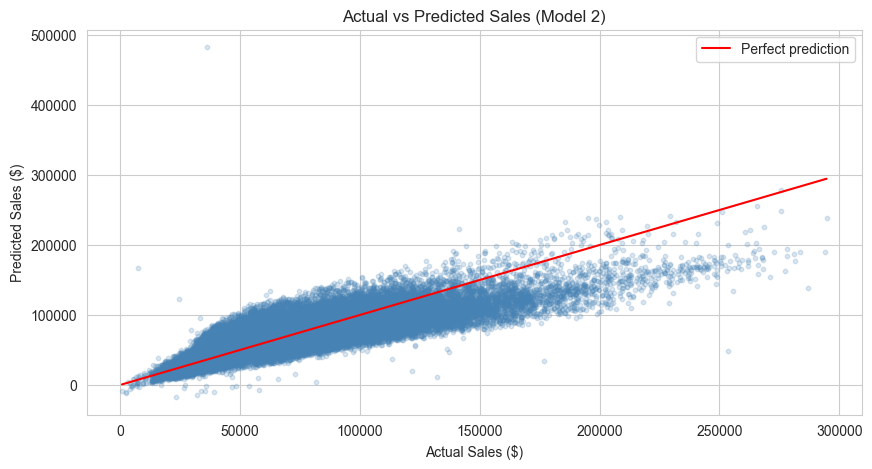

In [15]:
fig, ax = plt.subplots()
ax.scatter(y2_test, pred2, alpha=0.2, s=10, color="steelblue")
ax.plot([y2_test.min(), y2_test.max()], [y2_test.min(), y2_test.max()],
        color="red", linewidth=1.5, label="Perfect prediction")
ax.set_xlabel("Actual Sales ($)")
ax.set_ylabel("Predicted Sales ($)")
ax.set_title("Actual vs Predicted Sales (Model 2)")
ax.legend()
save(fig, "10_actual_vs_predicted")
plt.show()

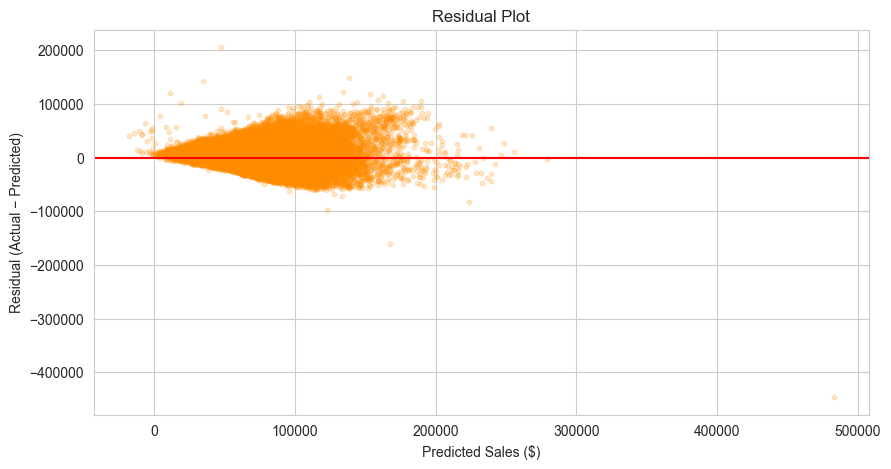

In [16]:
residuals = y2_test - pred2

fig, ax = plt.subplots()
ax.scatter(pred2, residuals, alpha=0.2, s=10, color="darkorange")
ax.axhline(0, color="red", linewidth=1.5)
ax.set_xlabel("Predicted Sales ($)")
ax.set_ylabel("Residual (Actual − Predicted)")
ax.set_title("Residual Plot")
save(fig, "11_residual_plot")
plt.show()

In [25]:
import joblib, json

joblib.dump(model2, "model2_multiple_regression.pkl")

summary = {
    "model1_coef_footfall": float(model1.coef_[0]),
    "model1_intercept": float(model1.intercept_),
    "model1_r2": float(r2_1), "model1_mae": float(mae_1), "model1_rmse": float(rmse_1),
    "model2_r2": float(r2_2), "model2_mae": float(mae_2), "model2_rmse": float(rmse_2),
    "model2_coef_footfall": float(coef_table["custcoun"]),
}
with open("model_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved model2_multiple_regression.pkl and model_summary.json")

Saved model2_multiple_regression.pkl and model_summary.json


In [26]:
footfall_coef = model2.coef_[list(features.columns).index("custcoun")]

impact_per_100 = footfall_coef * 100

print("FOOTFALL IMPACT ON SALES")
print(f"  Each additional customer is associated with an average change")
print(f"  of ${footfall_coef:,.2f} in sales, holding day-of-week and month constant.")
print()
print(f"  If footfall increases by 100 customers, the model estimates an")
print(f"  average change of ${impact_per_100:,.2f} in sales, holding the")
print(f"  other included variables constant.")

FOOTFALL IMPACT ON SALES
  Each additional customer is associated with an average change
  of $27.68 in sales, holding day-of-week and month constant.

  If footfall increases by 100 customers, the model estimates an
  average change of $2,767.99 in sales, holding the
  other included variables constant.


In [27]:
avg_daily_sales = df["Total_Sales"].mean()
pct_impact = (impact_per_100 / avg_daily_sales) * 100

print(f"Average daily sales per store: ${avg_daily_sales:,.2f}")
print(f"100 extra customers ≈ {pct_impact:.2f}% of an average day's sales")

Average daily sales per store: $66,020.14
100 extra customers ≈ 4.19% of an average day's sales


In [28]:
store_impact = []

for store_id, g in df.groupby("store"):
    if len(g) < 100:
        continue
    Xs = g[["custcoun"]]
    ys = g["Total_Sales"]
    m = LinearRegression().fit(Xs, ys)
    store_impact.append({
        "store": store_id,
        "coef_per_customer": m.coef_[0],
        "avg_footfall": g["custcoun"].mean(),
        "avg_sales": g["Total_Sales"].mean(),
        "n_days": len(g)
    })

store_impact_df = pd.DataFrame(store_impact).sort_values("coef_per_customer", ascending=False)
print("Top 5 stores - highest sales per extra customer:")
print(store_impact_df.head(5).to_string(index=False))
print("\nBottom 5 stores - lowest sales per extra customer:")
print(store_impact_df.tail(5).to_string(index=False))

store_impact_df.to_csv("store_level_impact.csv", index=False)

Top 5 stores - highest sales per extra customer:
 store  coef_per_customer  avg_footfall     avg_sales  n_days
   316          55.491502   2269.859649  86976.497873    1368
   307          54.776146   2992.974717 104777.837119    2936
   301          54.052554   3477.114696 129721.104844    2979
   129          51.882095   2413.528670  77534.437974    2616
   137          51.288826   3075.210370  99228.244607    2353

Bottom 5 stores - lowest sales per extra customer:
 store  coef_per_customer  avg_footfall    avg_sales  n_days
    75          16.521906   3398.646257 47925.144105    2979
    33          16.253521   3252.861096 44932.773315    2983
   117          14.379785   2045.936112 41348.333888    2639
    64          14.195267   1731.008942 35001.847147    2173
    10           9.757317   1800.477273 32735.030303     132


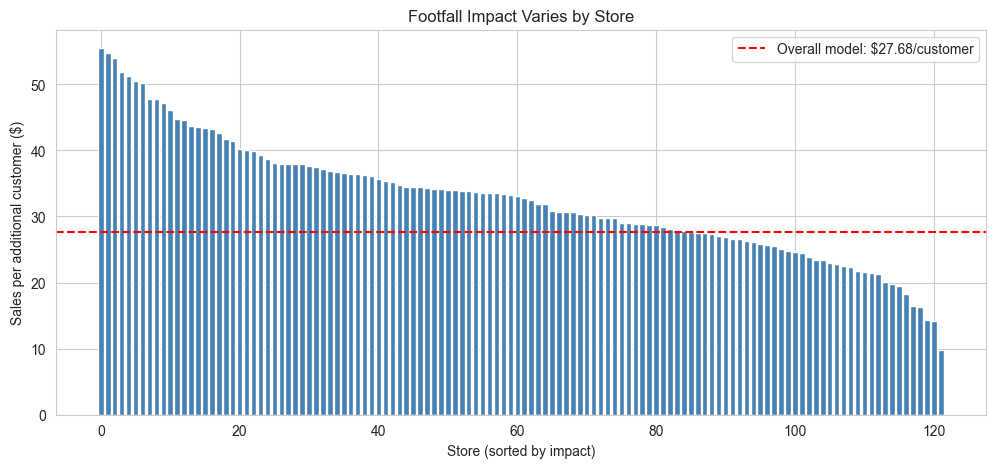

In [29]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(store_impact_df)), store_impact_df["coef_per_customer"], color="steelblue")
ax.axhline(footfall_coef, color="red", linestyle="--", label=f"Overall model: ${footfall_coef:.2f}/customer")
ax.set_xlabel("Store (sorted by impact)")
ax.set_ylabel("Sales per additional customer ($)")
ax.set_title("Footfall Impact Varies by Store")
ax.legend()
save(fig, "12_store_level_impact")
plt.show()

In [30]:
## Impact Analysis Summary

- Overall model: each additional customer is associated with **$X.XX** more in daily sales (holding day-of-week and month constant).
- 100 extra customers ≈ **$X,XXX** in additional daily sales, or roughly **X.X%** of an average store-day's revenue.
- Impact is not uniform: the highest-converting stores earn several times more per extra customer than the lowest, suggesting factors beyond raw traffic (store size, local demographics, product mix) also matter.

SyntaxError: invalid character '≈' (U+2248) (3822838893.py, line 4)